# 12. Observability and model comparison

## Problem

A readiness answer is slow or wrong. Determine whether the failure came from retrieval, context selection, generation, orchestration or authorization without exporting private policy text.

## Learning objectives

Create actual Langfuse spans; inspect trace parentage and timings; verify privacy defaults; compare controlled trials; distinguish measured usage from estimates and missing data.

Run top to bottom in a fresh kernel. The default path uses temporary storage and scripted inference with actual framework orchestration. Every plotted value is labelled measured, estimated or illustrative.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings(_env_file=None, deep_lab_mode="demo", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "demo" and not settings.langfuse_enabled

## Concept explanation

## Trace structure

A trace represents one logical request or unit of work.

Spans or observations describe its internal operations.

The trace should make it possible to answer:

- Which model configuration was used?
- Which tools were called, with what validated arguments?
- Which evidence IDs were retrieved?
- Which source revisions were considered?
- Where did latency accumulate?
- Was an action approved, edited, rejected, or stale?
- Which saved artifact resulted from the run?

These are observable facts. Debugging should not depend on exposing hidden model reasoning.

## Langfuse instrumentation

Your repository already provides optional Langfuse tracing and privacy controls.

The notebook exercises the installed Langfuse Python SDK with an OpenTelemetry in-memory exporter, then inspects real span parentage and timings. It uses the existing tracing wrapper and sends no content to an external backend.

The same instrumentation can be expressed with decorators or manual observations.

The important design is the trace hierarchy, not the specific syntax.

Langfuse's SDKs use OpenTelemetry concepts and support nested observations and evaluation workflows. The repository's declared `langfuse>=5,<6` contract aligns with the Python v5 major.

## Privacy-aware tracing

Avoid storing raw prompts and responses by default when they may contain confidential information.

An informative trace can often use evidence IDs, query hashes, model identifiers, result counts, timings, and error classifications.

```
{
  "run_id": "run-123",
  "thread_id": "thread-456",
  "operation": "hybrid_retrieval",
  "keyword_results": 10,
  "vector_results": 10,
  "final_results": 4,
  "duration_ms": 125,
  "status": "success"
}
```

These values are illustrative.

Also remember that metadata itself can contain sensitive data. Hashing a short or predictable secret is not necessarily sufficient anonymization.

The safest approach depends on organizational data classification, retention, and threat model.

## Diagnosing failure types

A useful diagnostic method follows the execution sequence.

| Symptom                               | Most useful first inspection                 |
| ------------------------------------- | -------------------------------------------- |
| Correct document absent               | Retrieval candidates, index, source revision |
| Correct passage retrieved but omitted | Context selection and truncation             |
| Evidence present but answer false     | Claim generation and support check           |
| Wrong tool chosen                     | Tool schema and model trajectory             |
| Repeated tool calls                   | Agent policy and loop limits                 |
| Save occurred unexpectedly            | Authorization and approval logs              |
| Duplicate brief                       | Idempotency records and write timeline       |
| Slow request                          | Span durations and model/tool resource usage |

This separation prevents you from changing prompts when the problem is actually in the search index.

## Bounded repair loops

A model may produce an answer without citations even though the retrieval result contains good evidence.

Your repository already implements a limited citation-repair mechanism for live mode.

That is a useful pattern if it is bounded and observable.

A general repair policy might be:

```
Generate answer
    ↓
Validate required structure
    ↓
If invalid and repair budget remains:
    provide targeted feedback
    ↓
Regenerate once
    ↓
Validate again
    ↓
Accept or fail safely
```

Avoid unbounded self-criticism loops.

The validator should provide concrete feedback, such as "claim C2 cites an unknown evidence ID," rather than a vague instruction to make the answer better.

## Model selection

Different models can vary in tool-calling reliability, structured output quality, instruction following, latency, context capacity, and resource requirements.

Northstar should evaluate models on its own task distribution.

Do not assume that a model with a larger parameter count is automatically better for every Northstar task.

### **Controlled comparison**

Use the same dataset and, as far as possible, the same retrieval settings, prompts, tool contracts, inference parameters, and hardware conditions.

Record:

| Dimension              | Why it matters                     |
| ---------------------- | ---------------------------------- |
| Task success           | Core usefulness                    |
| Claim support          | Factual reliability                |
| Tool-call correctness  | Agent reliability                  |
| Appropriate abstention | Avoiding unsupported answers       |
| Latency                | User experience                    |
| Context requirements   | Capacity planning                  |
| Peak memory/VRAM       | Local feasibility                  |
| Tokens per second      | Local inference throughput         |
| Hosted API cost        | Operating expense where applicable |

### **Local inference versus hosted pricing**

A hosted API often charges according to input tokens, output tokens, and provider-specific pricing.

Local Ollama inference has different economics.

You may not pay a per-token provider bill, but you still consume CPU/GPU resources, memory, power, and engineering time.

Approximate local operating cost can be modeled as:

$$ C_{\text{local}} = C_{\text{electricity}} + C_{\text{hardware amortization}} + C_{\text{operations}} $$

This is not directly comparable to hosted token prices without accounting for workload, utilization, capacity, and service-level requirements.

No model benchmark or cost claim in this course should be considered measured until an experiment actually produces the corresponding data.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

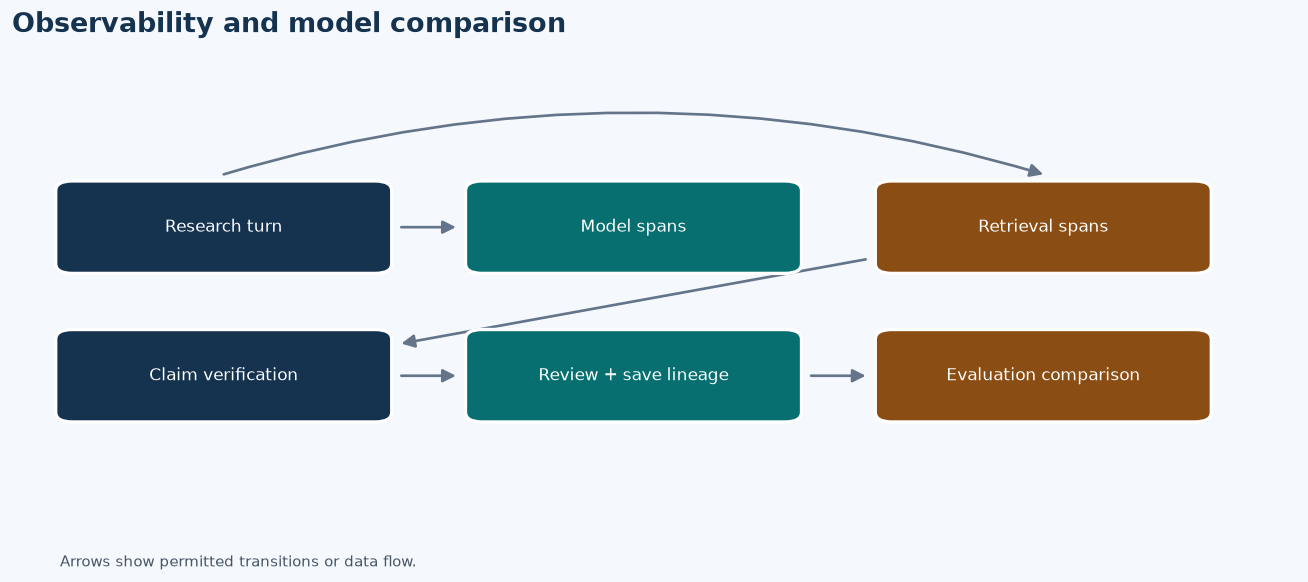

In [2]:
display(diagram('Observability and model comparison', ['Research turn', 'Model spans', 'Retrieval spans', 'Claim verification', 'Review + save lineage', 'Evaluation comparison'], [(0, 1), (0, 2), (2, 3), (3, 4), (4, 5)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
from time import perf_counter
from contextlib import contextmanager
events = []
@contextmanager
def timed(name):
    start = perf_counter()
    try:
        yield
    finally:
        events.append({"name":name,"duration_ms":(perf_counter()-start)*1000})
with timed("search"):
    from deep_agent_lab.knowledge import fixture_search
    rows = fixture_search("restore",3)
assert events[0]["duration_ms"] > 0
print(events)

[{'name': 'search', 'duration_ms': 199.8273999997764}]


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Any fixture ports or scripted responses are identified in the cell.

In [4]:
from uuid import uuid4
from unittest.mock import patch
from langfuse import Langfuse
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter
from deep_agent_lab.tracing import Tracing
from deep_agent_lab.service import AgentService,RunRequest,open_checkpointer
exporter = InMemorySpanExporter()
client = Langfuse(public_key="pk-local-"+uuid4().hex,secret_key="sk-local-fixture",
                 base_url="https://langfuse.example",tracer_provider=TracerProvider(),span_exporter=exporter)
traced_settings = settings.model_copy(update={"langfuse_enabled":True,
    "langfuse_public_key":"pk-fixture","langfuse_capture_content":False})
with patch.object(Tracing,"_create_client",staticmethod(lambda configuration:client)):
    with open_checkpointer(traced_settings) as cp:
        service = AgentService(traced_settings,cp)
        try:
            result = service.run(RunRequest(prompt="Who approves a production restore?"))
            client.flush()
            spans = exporter.get_finished_spans()
        finally:
            service.close()
assert result.trace_id and {span.name for span in spans} == {"deep-lab.turn","deep-lab.model","deep-lab.search"}
assert len({span.context.trace_id for span in spans}) == 1
for span in spans:
    assert "langfuse.observation.input" not in span.attributes
    assert "langfuse.observation.output" not in span.attributes
print("Actual SDK spans captured locally; nothing was sent to a Langfuse server.")

Actual SDK spans captured locally; nothing was sent to a Langfuse server.


## Code walkthrough

The experiment uses the installed Langfuse SDK and an OpenTelemetry in-memory exporter. Span creation and parent relationships are real; the remote backend is deliberately absent. The application wrapper suppresses input and output content by default and records sanitized exception types. Metadata still needs a deliberate schema because content suppression cannot sanitize arbitrary values. A trace records what happened, while an evaluation judges whether it was correct. Compare models with the same cases, prompts, tool contracts, retrieval and hardware conditions; retain each trial.

## Interactive experiments

Plot the actual captured span durations. Parent spans contain child time, so summing all spans double-counts work. Use a timeline to understand overlap.

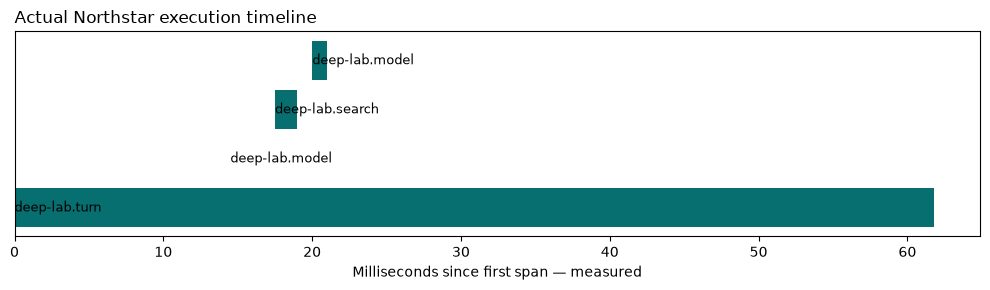

In [5]:
origin = min(span.start_time for span in spans)
fig,ax = plt.subplots(figsize=(10,3))
for index,span in enumerate(sorted(spans,key=lambda s:s.start_time)):
    start = (span.start_time-origin)/1e6
    duration = (span.end_time-span.start_time)/1e6
    ax.barh(index,duration,left=start,color="#076f70")
    ax.text(start,index,span.name,va="center",fontsize=9)
ax.set_xlabel("Milliseconds since first span — measured")
ax.set_yticks([])
ax.set_title("Actual Northstar execution timeline",loc="left")
fig.tight_layout()
display(fig)
plt.close("all")

## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
class BrokenClient:
    def start_as_current_observation(self,**kwargs):
        raise RuntimeError("synthetic exporter failure")
broken = Tracing()
broken.client = BrokenClient()
with broken.span("still-functional"):
    answer = fixture_search("restore",1)
assert answer
print("Telemetry failure did not break research.")

Langfuse observation failed (RuntimeError)


Telemetry failure did not break research.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
root_span = next(span for span in spans if span.name == "deep-lab.turn")
children = [span for span in spans if span.name != "deep-lab.turn"]
assert all(span.parent and span.parent.span_id == root_span.context.span_id for span in children)
assert all(span.end_time >= span.start_time for span in spans)

## Exercise

Calculate observed search and model time without inventing token counts or prices. Describe which additional measurements are needed for hosted and local cost estimates.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
durations = {}
for span in spans:
    durations[span.name] = durations.get(span.name,0)+(span.end_time-span.start_time)/1e6
usage = {"input_tokens":None,"output_tokens":None,"hosted_cost":None,"local_power_kwh":None}
assert durations["deep-lab.turn"] > 0 and usage["hosted_cost"] is None
print("Measured durations:",durations,"Unmeasured resources:",usage)

Measured durations: {'deep-lab.model': 0.9997, 'deep-lab.search': 1.5026, 'deep-lab.turn': 61.788} Unmeasured resources: {'input_tokens': None, 'output_tokens': None, 'hosted_cost': None, 'local_power_kwh': None}


## Trade-offs and further reading

Capture only telemetry you can use and retain responsibly. Scripted model timing does not predict Ollama performance. Hosted token prices, power, VRAM and hardware amortization require separate measured inputs; a missing value is not zero.

[Primary source 1](https://langfuse.com/docs/observability/sdk/overview) · [Primary source 2](https://langfuse.com/docs/observability/data-model)

## Optional live integration

Install Ollama and initialize/ingest the configured PostgreSQL/OpenSearch corpus as described in `docs/operations.md`. Set RUN_LIVE only when those dependencies are available. This cell is skipped in offline verification. A successful live run still requires claim-level review; token and cost measurements are only meaningful when the provider reports them.

In [9]:
RUN_LIVE = False
if RUN_LIVE:
    from deep_agent_lab.service import AgentService, RunRequest, open_checkpointer
    live = Settings(_env_file=ROOT / ".env", deep_lab_mode="live")
    with open_checkpointer(live) as cp:
        service = AgentService(live, cp)
        try:
            result = service.run(RunRequest(
                prompt="Who approves a production restore? Cite the policy."))
            print(result.model_dump_json(indent=2))
            assert result.evidence and not result.unknown_citations
        finally:
            service.close()

In [10]:
plt.close('all')
scratch.cleanup()
print('All offline module assertions passed.')

All offline module assertions passed.
